# Model Predictive Control of a Conveyor: Horizon, Constraints and What It Buys over PI

`12_mpc` | level 5 | experiment id(s): `exp_12_mpc_conveyor`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 4 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Build the condensed quadratic program of a linear MPC and verify it against an independent finite-horizon
  Riccati recursion and against the infinite-horizon LQR gain.
- Check a constrained QP solution against two different solvers, and check that a closed-loop run respects the
  input and slew limits.
- State, with numbers, when MPC beats a well-tuned PI on a stable single-input plant and when it does not.
- Explain why an optimiser that ignores the actuator limit performs worse than one that includes it.
- Read the real-time cost of the QP on the machine that ran it, without treating it as an embedded figure.

## 2. Real-World Engineering Problem

The conveyor of notebook 11 must hold or change belt speed with a drive that has three limits: command
between 0 and 1, a maximum slew rate (protecting the drive and the load), and a force ceiling that makes some
speeds unreachable when the payload is large. A PI loop handles the first with anti-windup, the second with an
external rate limiter that the integrator does not know about, and the third with anti-windup again. MPC puts
all three into the optimisation. The question is how much that buys here, measured, and at what computing cost.

## 3. Research Background

MPC with input constraints is surveyed by Mayne et al. (2000), with stability conditions (terminal cost or set) that this
implementation does not have; Rawlings, Mayne and Diehl (2017) is the textbook. PI comparators use the SIMC rule
(Skogestad, 2003) with the anti-windup of Astrom and Hagglund (1995).

## 4. Research Literature

The references are cited for the method. The condensed formulation is standard; the implementation in
`control_lab.controllers.mpc` is not code-generated, has no terminal ingredients, uses a general-purpose solver
(SciPy) and offers no stability guarantee. Its quality here rests on the checks in section 12, not on the cited
theory. No post-2020 MPC literature was searched in this build.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| mayne2000 | Mayne, D. Q.; Rawlings, J. B.; Rao, C. V.; Scokaert, P. O. M. (2000). Constrained model predictive control: Stability and optimality. Automatica, 36(6), 789-814. doi:10.1016/S0005-1098(99)00214-9. | Survey of the conditions (terminal cost/constraint) that give MPC stability. | The controller built in this repository has no terminal ingredients, so these guarantees do not apply to it. | verified (2026-11-25, web search of publisher/index/library record). dblp and an index record agree on venue, volume, issue and pages. |
| rmd2017 | Rawlings, J. B.; Mayne, D. Q.; Diehl, M. M. (2017). Model Predictive Control: Theory, Computation, and Design, 2nd ed.. Nob Hill Publishing. ISBN 978-0-9759377-3-0. | Textbook treatment of linear and nonlinear MPC, estimation and stability. | Theory heavy; implementation details of real-time solvers are limited. | verified (2026-11-25, web search of publisher/index/library record). Author-hosted front matter gives publisher and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| skogestad2003 | Skogestad, S. (2003). Simple analytic rules for model reduction and PID controller tuning. Journal of Process Control, 13(4), 291-309. doi:10.1016/S0959-1524(02)00062-8. | SIMC rules and the half rule for effective delay. | An erratum exists (J. Process Control 14, 2004, p. 465). | verified (2026-11-25, web search of publisher/index/library record). Author-hosted record and an index record agree; the erratum was seen. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Model $x_{k+1}=Ax_k+Bu_k$, $y_k=Cx_k$ in deviation variables around an operating point. Over $N$ steps,
$Y=\Phi x_0+\Gamma U$, and the cost
$$J=\sum_{k=1}^{N}(y_k-r)^\top Q(y_k-r)+\sum_{k=0}^{N-1}\Delta u_k^\top R\,\Delta u_k,\quad \Delta u_k=u_k-u_{k-1}$$
becomes the QP $\min_U\ \tfrac12U^\top HU+f^\top U$ with $H=\Gamma^\top\bar Q\Gamma+D^\top\bar RD$, subject to
$u_{min}\le u_k\le u_{max}$ and $|\Delta u_k|\le\Delta u_{max}$. Only the first move is applied (receding horizon).

**Offset-free action.** The output disturbance estimate $\hat d=y-Cx_{model}$ is held constant over the horizon,
so a constant disturbance or a plant-model mismatch of a stable plant leaves no steady offset.

**Independent references.**
(a) Backward Riccati recursion on the augmented state $z=[x;u_{-1}]$ with input $\Delta u$ gives the exact
unconstrained first move for the same finite horizon.
(b) As $N\to\infty$, the unconstrained first move tends to $\Delta u_0=-K_zz_0$ with $K_z$ from the discrete algebraic
Riccati equation of the same augmented system. The stage cost uses $z_{k+1}$, so the equivalent weights are
$Q_s=A_z^\top Q_zA_z$, $R_s=R+B_z^\top Q_zB_z$, cross term $N_s=A_z^\top Q_zB_z$.
(c) A box-constrained QP is a bounded least-squares problem: with $H=LL^\top$,
minimise $\tfrac12\lVert L^\top U+L^{-1}f\rVert^2$ subject to bounds; a different algorithm (BVLS) solves it.
(d) The rate-constrained QP is re-solved with `trust-constr` instead of SLSQP.

## 6. System Modeling

Plant: the belt conveyor of notebook 11 (`m_belt = 12 kg`, `c = 40 N s/m`, `mu = 0.03`, `F_max = 40 N`, `tau_t = 50 ms`),
simulated with RK4 and 25 substeps per sample. **Sample time 50 ms** (5 times slower than notebook 11, to keep the
QP small). MPC model: two states `[v, F]`, input command, exact ZOH discretisation, linearised at the operating speed
0.5 m/s with the payload the model assumes; rolling friction is a constant absorbed in the operating command.
Weights `Q = 1`, `R = 0.01`, horizon `N = 20` (1.0 s) unless varied. Limits: command 0 to 1; slew 0.05 per
sample (1.0 per second) where stated. All runs start in steady state at 0.5 m/s (`v_init`). The PI comparator is notebook 11's scheduled
SIMC PI (`tau_c = 0.2 s`, dead time `L + Ts/2` to account for the slower sample), with back-calculation.

## 7. Dataset and Measurement Data

No dataset; everything is simulated. The payload is known exactly to both controllers where stated.

## 8. Algorithm Architecture

`MPCController` wraps `LinearMPC`: it keeps a model state, computes the disturbance estimate each sample, solves the QP,
applies the first move and returns `u_op + u_dev`. Bounds are passed in deviation form. A variant ignoring the bounds
(`constrained=False`) is used to show what the constraints are worth; the plant still clips the command to 0..1.

## 9. Algorithm Implementation

In [2]:
import pandas as pd
from scipy.linalg import solve_discrete_are
from scipy.optimize import Bounds, LinearConstraint, lsq_linear, minimize
from control_lab.controllers import PID, LinearMPC, MPCController
from control_lab.controllers.tuning import simc_pi
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import iae, step_response_metrics, total_variation
from control_lab.models import BeltConveyor, ConveyorParams, c2d_zoh
from control_lab.simulation import run_closed_loop
from control_lab.simulation.loop import Actuator

EXP = "exp_12_mpc_conveyor"
P = ConveyorParams()
Ts, V0, DU = 0.05, 0.5, 0.05
C = np.array([[1.0, 0.0]])
ID = dict(K=1.0008, T=0.31067, L=0.04283)    # identification result of notebook 11 (exp_11 JSON)

def model(mp):
    m = P.m_belt + mp
    Ac = np.array([[-P.c / m, 1.0 / m], [0.0, -1.0 / P.tau_t]]); Bc = np.array([[0.0], [P.F_max / P.tau_t]])
    return c2d_zoh(Ac, Bc, Ts)

def u_op_for(mp):
    return BeltConveyor(P).command_for_speed(V0, mp)

def make_mpc(mp_model, N=20, R=0.01, du_max=None, constrained=True):
    Ad, Bd = model(mp_model); uo = u_op_for(mp_model)
    kw = dict(u_min=-uo, u_max=1.0 - uo) if constrained else {}
    m = LinearMPC(Ad, Bd, C, N=N, Q=np.array([[1.0]]), R=np.array([[R]]), du_max=du_max, **kw)
    return MPCController(m, V0, uo)

class PIs:
    # scheduled SIMC PI at the 50 ms sample, started in steady state
    def __init__(self, belt, u_init, tau_c=0.2, aw="backcalc"):
        self.belt, self.u_init, self.tau_c = belt, u_init, tau_c
        self.pid = PID.from_times(1.0, 1.0, 0.0, Ts=Ts, u_min=0.0, u_max=1.0, antiwindup=aw); self._g()
    def _g(self):
        Tm = ID["T"] * (P.m_belt + self.belt.m_payload) / P.m_belt
        q = simc_pi(ID["K"], Tm, ID["L"] + Ts / 2, tau_c=self.tau_c)
        self.pid.kp, self.pid.ki, self.pid.tt = q["kp"], q["kp"] / q["ti"], q["ti"]
    def reset(self):
        self.pid.reset(); self._g(); self.pid.track(self.u_init, V0, V0)
    def update(self, r, y):
        self._g(); return self.pid.update(r, y)

def run(kind, ref, t_end, mp0=5.0, events=None, actuator=None, mp_model=None, **kw):
    belt = BeltConveyor(P, Ts=Ts, substeps=25, m_payload=mp0, payload_events=events, v_init=V0)
    if kind == "PI":
        ctl = PIs(belt, u_op_for(mp0), tau_c=kw.get("tau_c", 0.2), aw=kw.get("aw", "backcalc"))
    else:
        ctl = make_mpc(mp0 if mp_model is None else mp_model, N=kw.get("N", 20), R=kw.get("R", 0.01), du_max=kw.get("du_max"), constrained=kw.get("constrained", True))
    n = int(round(t_end / Ts)); t = np.arange(n) * Ts
    o = run_closed_loop(belt, ctl, ref(t), Ts, actuator=actuator)
    o["ctl"] = ctl
    return o

def recovery(o, ref, t0, band):
    k0 = int(round(t0 / Ts)); out = np.flatnonzero(np.abs(o["y"][k0:] - ref) > band)
    return float(out[-1] * Ts) if out.size else 0.0

def solve_stats(o):
    s = getattr(o["ctl"], "solve_times", [])
    return (1e3 * float(np.mean(s)), 1e3 * float(np.max(s)), int(o["ctl"].failures)) if s else (0.0, 0.0, 0)

`ID` is copied from the experiment record of notebook 11 (`K = 1.0008`, `T = 0.3107 s`, `L = 0.0428 s`), so
the PI comparator uses the same identified model rather than the true plant parameters. The MPC model uses the true
plant parameters (a best case for MPC; the effect of a wrong payload is tested in section 12).

## 10. Simulation and Numerical Analysis

Section 12 runs: (a) algorithm verification without a plant (Riccati, LQR convergence, two QP solvers);
(b) a step toward the drive ceiling with and without the constraints in the optimiser and a horizon sweep;
(c) a slew-limited step; (d) a PI/MPC trade-off over tuning (IAE against total variation of the command);
(e) an item drop with the right and wrong payload in the model; (f) the unreachable reference of notebook 11.

## 11. Experimental Validation

Level: **software simulation**. Independent references: backward Riccati recursion, the discrete algebraic Riccati
equation, SciPy BVLS (`lsq_linear`) and `trust-constr` for the QP. Closed-loop comparisons are simulation
results; no embedded solver, hardware-in-the-loop run or conveyor was used.

## 12. Performance Evaluation

In [3]:
checks = []
rng = np.random.default_rng(12)

# --- (a) algorithm verification without a plant
def riccati_first_move(Ad, Bd, N, Q, R, x0, u_prev, r):
    n = Ad.shape[0]
    Az = np.block([[Ad, Bd], [np.zeros((1, n)), np.eye(1)]]); Bz = np.vstack([Bd, np.eye(1)]); Cz = np.hstack([C, np.zeros((1, 1))])
    Aa = np.block([[Az, np.zeros((n + 1, 1))], [np.zeros((1, n + 1)), np.ones((1, 1))]]); Ba = np.vstack([Bz, np.zeros((1, 1))])
    Ca = np.hstack([Cz, -r * np.ones((1, 1))])
    Pm = np.zeros((n + 2, n + 2))
    for _ in range(N):
        W = Ca.T * Q @ Ca + Pm
        Kf = np.linalg.solve(Ba.T @ W @ Ba + R, Ba.T @ W @ Aa)
        Pm = Aa.T @ W @ Aa - Aa.T @ W @ Ba @ Kf
    z0 = np.concatenate([x0, u_prev, [1.0]])
    return float(-(Kf @ z0)[0])

Ad, Bd = model(5.0)
m15 = LinearMPC(Ad, Bd, C, N=15, Q=np.array([[1.0]]), R=np.array([[0.01]]))
errs = []
for _ in range(20):
    x0 = rng.normal(size=2) * [0.1, 2.0]; up = float(rng.normal() * 0.2); r_ = float(rng.normal() * 0.1)
    U = m15.solve_unconstrained(x0, r_, up)
    errs.append(abs((U[0] - up) - riccati_first_move(Ad, Bd, 15, 1.0, 0.01, x0, np.array([up]), r_)))
checks.append(check("finite-horizon unconstrained first move equals the Riccati recursion (20 random states, N = 15)", max(errs) < 1e-6, f"max abs diff {max(errs):.2e}"))

Az = np.block([[Ad, Bd], [np.zeros((1, 2)), np.eye(1)]]); Bz = np.vstack([Bd, np.eye(1)]); Cz = np.hstack([C, np.zeros((1, 1))])
Qz = Cz.T @ Cz * 1.0; Qs = Az.T @ Qz @ Az; Rs = np.array([[0.01 + (Bz.T @ Qz @ Bz)[0, 0]]]); Ns = Az.T @ Qz @ Bz
Pd = solve_discrete_are(Az, Bz, Qs, Rs, s=Ns)
K_lqr = np.linalg.solve(Bz.T @ Pd @ Bz + Rs, Bz.T @ Pd @ Az + Ns.T)[0]
gain_err = {}
for N in (2, 5, 10, 20, 40):
    mN = LinearMPC(Ad, Bd, C, N=N, Q=np.array([[1.0]]), R=np.array([[0.01]]))
    g = np.array([mN.solve_unconstrained(np.eye(3)[j][:2], 0.0, np.eye(3)[j][2])[0] - np.eye(3)[j][2] for j in range(3)])
    gain_err[N] = float(np.linalg.norm(g + K_lqr) / np.linalg.norm(K_lqr))
print("LQR gain", np.round(K_lqr, 4), {k: f"{v:.1e}" for k, v in gain_err.items()})
checks.append(check("MPC first-move gain error against the LQR gain falls with horizon (N = 2, 5, 10, 20)", gain_err[2] > gain_err[5] > gain_err[10] > gain_err[20], f"{gain_err[2]:.1e} > {gain_err[5]:.1e} > {gain_err[10]:.1e} > {gain_err[20]:.1e}"))
checks.append(check("MPC first-move gain at N = 40 equals the LQR gain within 1e-6 (relative)", gain_err[40] < 1e-6, f"{gain_err[40]:.1e}"))

# box-constrained QP against bounded least squares
mb = LinearMPC(Ad, Bd, C, N=20, Q=np.array([[1.0]]), R=np.array([[0.01]]), u_min=-0.3, u_max=0.3)
dbox, n_active = [], 0
for _ in range(15):
    x0 = rng.normal(size=2) * [0.2, 2.0]; up = float(rng.uniform(-0.3, 0.3)); r_ = float(rng.normal() * 0.3)
    U, info = mb.solve(x0, r_, up)
    f = mb._linear_term(x0, r_, up, 0.0); L = np.linalg.cholesky(mb.H)
    sol = lsq_linear(L.T, -np.linalg.solve(L, f), bounds=(np.full(20, -0.3), np.full(20, 0.3)), method="bvls", tol=1e-12)
    n_active += int(np.any(np.isclose(np.abs(U), 0.3, atol=1e-6)))
    dbox.append(abs(mb.cost(U, x0, r_, up) - mb.cost(sol.x, x0, r_, up)) / max(1.0, abs(mb.cost(sol.x, x0, r_, up))))
checks.append(check("box-constrained QP cost equals bounded least squares (BVLS) cost on 15 states, bounds active in most", max(dbox) < 1e-8 and n_active >= 8, f"max rel diff {max(dbox):.1e}, bounds active in {n_active}/15"))

# rate-constrained QP: KKT optimality certificate, and comparison with trust-constr
from scipy.optimize import nnls
mr = LinearMPC(Ad, Bd, C, N=20, Q=np.array([[1.0]]), R=np.array([[0.01]]), u_min=-0.3, u_max=0.3, du_max=DU)
kkt_rel, diff_vs_tc, viol = [], [], 0.0
for _ in range(5):
    x0 = rng.normal(size=2) * [0.2, 2.0]; up = float(rng.uniform(-0.2, 0.2)); r_ = float(rng.normal() * 0.3)
    U, info = mr.solve(x0, r_, up)
    f = mr._linear_term(x0, r_, up, 0.0); g = mr.H @ U + f
    dd = mr.D @ U - mr.S @ np.array([up]); rows = []
    for j in range(len(U)):
        if 0.3 - U[j] < 1e-6: rows.append(np.eye(len(U))[j])
        if U[j] + 0.3 < 1e-6: rows.append(-np.eye(len(U))[j])
    for i in range(len(U)):
        if DU - dd[i] < 1e-6: rows.append(mr.D[i])
        if DU + dd[i] < 1e-6: rows.append(-mr.D[i])
    res_k = nnls(np.array(rows).T, -g)[1] if rows else float(np.linalg.norm(g))
    kkt_rel.append(res_k / max(float(np.linalg.norm(g)), 1e-12))
    cons = LinearConstraint(mr.D, mr.S @ np.array([up]) - DU, mr.S @ np.array([up]) + DU)
    tc = minimize(lambda V: 0.5 * V @ mr.H @ V + f @ V, np.clip(U, -0.3, 0.3), jac=lambda V: mr.H @ V + f, hess=lambda V: mr.H,
                  bounds=Bounds(-0.3, 0.3), constraints=cons, method="trust-constr", options={"gtol": 1e-10, "xtol": 1e-12, "maxiter": 5000})
    c_s, c_t = mr.cost(U, x0, r_, up), mr.cost(tc.x, x0, r_, up)
    diff_vs_tc.append((c_s - c_t) / max(1.0, abs(c_t)))
    viol = max(viol, float(np.max(np.abs(dd) - DU)), float(np.max(np.abs(U) - 0.3)))
checks.append(check("rate-constrained QP satisfies the KKT conditions (non-negative multipliers, relative residual < 1e-4) and its limits to 1e-6", max(kkt_rel) < 1e-4 and viol < 1e-6, f"max relative KKT residual {max(kkt_rel):.1e}, worst violation {viol:.1e}"))
checks.append(check("rate-constrained QP cost is not above the trust-constr cost (interior-point, strictly feasible, stops short)", max(diff_vs_tc) < 1e-9, f"SLSQP minus trust-constr, relative: {np.array(diff_vs_tc).round(8).tolist()}"))

# --- (b) step toward the drive ceiling, with and without the constraints in the optimiser
ceil5 = BeltConveyor(P).max_speed(5.0)
step85 = lambda t: np.where(t < 1.0, V0, 0.85)
runs_b = {"PI scheduled": run("PI", step85, 8.0), "MPC N=20, constrained": run("MPC", step85, 8.0),
          "MPC N=20, bounds ignored in QP": run("MPC", step85, 8.0, constrained=False)}
rows_b = []
for name, o in runs_b.items():
    k = int(1.0 / Ts); m = step_response_metrics(o["t"][k:] - 1.0, o["y"][k:], 0.85, y_initial=V0)
    mean_ms, max_ms, fails = solve_stats(o)
    rows_b.append(dict(controller=name, overshoot_pct=m["overshoot_percent"], rise_s=m["rise_time_10_90"], settling_s=m["settling_time"], iae=iae(o["t"], o["e"]),
                       requested_cmd_max=float(o["u"].max()), solve_ms_mean=mean_ms, solve_ms_max=max_ms, qp_failures=fails))
df_b = pd.DataFrame(rows_b); print(df_b.round(4).to_string(index=False))
iae_b = df_b.set_index("controller").iae
checks.append(check("constraint-aware MPC has lower IAE than MPC that ignores the bounds (saturating step)", iae_b["MPC N=20, constrained"] < iae_b["MPC N=20, bounds ignored in QP"], f"{iae_b['MPC N=20, constrained']:.4f} vs {iae_b['MPC N=20, bounds ignored in QP']:.4f}"))
rows_h = []
for N in (2, 5, 10, 20, 40):
    o = run("MPC", step85, 8.0, N=N); mean_ms, max_ms, fails = solve_stats(o)
    rows_h.append(dict(N=N, horizon_s=N * Ts, iae=iae(o["t"], o["e"]), solve_ms_mean=mean_ms, solve_ms_max=max_ms, qp_failures=fails))
df_h = pd.DataFrame(rows_h); print(df_h.round(5).to_string(index=False))
i10, i40 = df_h.set_index("N").iae[10], df_h.set_index("N").iae[40]
checks.append(check("closed-loop IAE changes by less than 0.1% between N = 10 and N = 40 (gain has converged by N = 10)", abs(i40 - i10) / i10 < 1e-3, f"{i10:.5f} vs {i40:.5f}"))

# --- (c) slew-limited step
step70 = lambda t: np.where(t < 1.0, V0, 0.7)
uo5 = u_op_for(5.0)
runs_c = {"PI + external rate limiter": run("PI", step70, 8.0, actuator=Actuator(0.0, 1.0, rate=DU, u0=uo5)),
          "MPC with slew constraint": run("MPC", step70, 8.0, du_max=DU),
          "PI, no slew limit": run("PI", step70, 8.0), "MPC, no slew limit": run("MPC", step70, 8.0)}
rows_c = []
for name, o in runs_c.items():
    k = int(1.0 / Ts); m = step_response_metrics(o["t"][k:] - 1.0, o["y"][k:], 0.7, y_initial=V0)
    mean_ms, max_ms, fails = solve_stats(o)
    rows_c.append(dict(controller=name, overshoot_pct=m["overshoot_percent"], rise_s=m["rise_time_10_90"], settling_s=m["settling_time"], iae=iae(o["t"], o["e"]),
                       max_step_du=float(np.max(np.abs(np.diff(np.r_[uo5, o["u"]])))), solve_ms_mean=mean_ms, solve_ms_max=max_ms, qp_failures=fails))
df_c = pd.DataFrame(rows_c); print(df_c.round(4).to_string(index=False))
u_s = runs_c["MPC with slew constraint"]["u"]
checks.append(check("slew-constrained MPC: command stays in [0, 1] and every step is within 0.05 (+1e-6)", bool(u_s.min() >= -1e-9 and u_s.max() <= 1 + 1e-9 and np.max(np.abs(np.diff(np.r_[uo5, u_s]))) <= DU + 1e-6), f"max step {np.max(np.abs(np.diff(np.r_[uo5, u_s]))):.6f}"))
iae_c = df_c.set_index("controller").iae
checks.append(check("with the slew limit, MPC has lower IAE than PI + external limiter", iae_c["MPC with slew constraint"] < iae_c["PI + external rate limiter"], f"{iae_c['MPC with slew constraint']:.4f} vs {iae_c['PI + external rate limiter']:.4f}"))

# horizon sweep under the slew limit, where a longer look-ahead has something to plan
rows_h2 = []
for N in (2, 5, 10, 20, 40):
    o = run("MPC", step70, 8.0, N=N, du_max=DU); mean_ms, max_ms, fails = solve_stats(o)
    k = int(1.0 / Ts); m = step_response_metrics(o["t"][k:] - 1.0, o["y"][k:], 0.7, y_initial=V0)
    rows_h2.append(dict(N=N, horizon_s=N * Ts, iae=iae(o["t"], o["e"]), overshoot_pct=m["overshoot_percent"], settling_s=m["settling_time"], solve_ms_mean=mean_ms, solve_ms_max=max_ms, qp_failures=fails))
df_h2 = pd.DataFrame(rows_h2); print(df_h2.round(5).to_string(index=False))

# --- (d) IAE against total variation, same step 0.5 -> 0.7, no slew limit
rows_d = []
for tc in (0.05, 0.1, 0.2, 0.4, 0.8):
    o = run("PI", step70, 6.0, tau_c=tc); rows_d.append(dict(controller="PI", setting=f"tau_c={tc}", iae=iae(o["t"], o["e"]), tv=total_variation(o["u"]), peak_step=float(np.max(np.abs(np.diff(o["u"]))))))
for R_ in (1e-4, 1e-3, 1e-2, 1e-1, 1.0):
    o = run("MPC", step70, 6.0, R=R_); rows_d.append(dict(controller="MPC", setting=f"R={R_:g}", iae=iae(o["t"], o["e"]), tv=total_variation(o["u"]), peak_step=float(np.max(np.abs(np.diff(o["u"]))))))
df_d = pd.DataFrame(rows_d); print(df_d.round(4).to_string(index=False))
pi_d, mpc_d = df_d[df_d.controller == "PI"], df_d[df_d.controller == "MPC"]
dominated = int(sum(((pi_d.iae <= r.iae) & (pi_d.tv <= r.tv)).any() for r in mpc_d.itertuples()))
dominating = int(sum(((mpc_d.iae <= r.iae) & (mpc_d.tv <= r.tv)).any() for r in pi_d.itertuples()))
print("MPC points dominated by a PI point:", dominated, "of 5; PI points dominated by an MPC point:", dominating, "of 5")

# --- (e) item drop, payload in the model right and wrong
rows_e, runs_e = [], {}
for name, kind, kw in [("PI scheduled", "PI", {}), ("MPC, model 5 kg (stale)", "MPC", {}), ("MPC, model 20 kg (correct)", "MPC", dict(mp_model=20.0))]:
    o = run(kind, lambda t: np.full(len(t), V0), 8.0, events=[(1.0, 15.0)], **kw); runs_e[name] = o
    k = int(1.0 / Ts)
    rows_e.append(dict(controller=name, dip=V0 - float(o["y"][k:].min()), recovery_s=recovery(o, V0, 1.0, 0.025), iae_after=iae(o["t"][k:], o["e"][k:]), ess=abs(V0 - float(o["y"][-1])), qp_failures=solve_stats(o)[2]))
df_e = pd.DataFrame(rows_e); print(df_e.round(4).to_string(index=False))
checks.append(check("MPC with a stale payload model has zero steady-state error after the drop (offset-free)", float(df_e.set_index("controller").loc["MPC, model 5 kg (stale)", "ess"]) < 1e-3, f"{float(df_e.set_index('controller').loc['MPC, model 5 kg (stale)', 'ess']):.2e} m/s"))

# --- (f) unreachable reference, 30 kg
def ref_hi(t): return np.where(t < 6.0, 0.8, 0.4)
rows_f, runs_f = [], {}
for name, kind, kw in [("PI back-calculation", "PI", {}), ("PI no anti-windup", "PI", dict(aw="none")), ("MPC, model 30 kg", "MPC", dict(mp_model=30.0)), ("MPC, model 5 kg (stale)", "MPC", dict(mp_model=5.0))]:
    o = run(kind, ref_hi, 16.0, mp0=30.0, **kw); runs_f[name] = o
    k = int(6.0 / Ts)
    rows_f.append(dict(controller=name, speed_before=float(o["y"][k - 1]), recovery_s=recovery(o, 0.4, 6.0, 0.02), min_after=float(o["y"][k:].min()), iae_after=iae(o["t"][k:], o["e"][k:]), qp_failures=solve_stats(o)[2]))
df_f = pd.DataFrame(rows_f).set_index("controller"); print(df_f.round(4))
ceil30 = BeltConveyor(P).max_speed(30.0)
checks.append(check("MPC speed at the ceiling is within 1% of the closed-form maximum (30 kg)", abs(df_f.loc["MPC, model 30 kg", "speed_before"] - ceil30) / ceil30 < 0.01, f"{df_f.loc['MPC, model 30 kg', 'speed_before']:.4f} vs {ceil30:.4f} m/s"))
all_fail = sum(int(x) for x in [df_b.qp_failures.sum(), df_h.qp_failures.sum(), df_h2.qp_failures.sum(), df_c.qp_failures.sum(), df_e.qp_failures.sum(), df_f.qp_failures.sum()])
checks.append(check("no QP solve reported failure in any closed-loop run", all_fail == 0, f"{all_fail} failures"))
worst_ms = max(df_b.solve_ms_max.max(), df_h.solve_ms_max.max(), df_h2.solve_ms_max.max(), df_c.solve_ms_max.max())
mean_ms_all = max(df_b.solve_ms_mean.max(), df_h.solve_ms_mean.max(), df_h2.solve_ms_mean.max(), df_c.solve_ms_mean.max())
checks.append(check("mean QP solve time is below 10% of the sample time in every run (this machine, SciPy)", mean_ms_all < 0.1 * 1e3 * Ts, f"worst run mean {mean_ms_all:.2f} ms against {0.1 * 1e3 * Ts:.0f} ms; single slowest solve {worst_ms:.1f} ms (not a check: timing outliers depend on the machine)"))

for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

LQR gain [4.0982 0.011  0.7231] {2: '1.9e-01', 5: '2.2e-03', 10: '1.9e-05', 20: '2.4e-09', 40: '2.2e-09'}


                    controller  overshoot_pct  rise_s  settling_s    iae  requested_cmd_max  solve_ms_mean  solve_ms_max  qp_failures
                  PI scheduled         0.0000  0.7512        1.35 0.1516             1.0000         0.0000        0.0000            0
         MPC N=20, constrained         0.1283  0.7508        1.10 0.1463             1.0000         0.3845        1.6226            0
MPC N=20, bounds ignored in QP         7.1326  0.7508        6.15 0.2546             2.4706         0.0639        0.2094            0


 N  horizon_s     iae  solve_ms_mean  solve_ms_max  qp_failures
 2       0.10 0.14632        0.34284       0.73206            0
 5       0.25 0.14627        0.35356       1.58865            0
10       0.50 0.14626        0.30324       0.58296            0
20       1.00 0.14626        0.32894       0.62687            0
40       2.00 0.14626        0.41736       1.09592            0


                controller  overshoot_pct  rise_s  settling_s    iae  max_step_du  solve_ms_mean  solve_ms_max  qp_failures
PI + external rate limiter         7.6101  0.3711        1.65 0.0857       0.0500         0.0000        0.0000            0
  MPC with slew constraint         1.9187  0.3619        0.60 0.0739       0.0500         0.4232        6.0732            0
         PI, no slew limit         0.0000  0.4039        0.90 0.0536       0.3657         0.0000        0.0000            0
        MPC, no slew limit         1.2660  0.2782        0.40 0.0434       0.3750         0.3427        1.0911            0


 N  horizon_s     iae  overshoot_pct  settling_s  solve_ms_mean  solve_ms_max  qp_failures
 2       0.10 0.07652        8.67142        0.85        0.29161       0.58044            0
 5       0.25 0.07395        2.06419        0.70        0.33082       1.25266            0
10       0.50 0.07390        1.92058        0.60        0.37554       1.68457            0
20       1.00 0.07390        1.91869        0.60        0.44109       6.15321            0
40       2.00 0.07390        1.91892        0.60        0.62734      13.42140            0


controller    setting    iae     tv  peak_step
        PI tau_c=0.05 0.0453 0.6152     0.3750
        PI  tau_c=0.1 0.0458 0.5689     0.3750
        PI  tau_c=0.2 0.0536 0.5505     0.3657
        PI  tau_c=0.4 0.0936 0.2501     0.2094
        PI  tau_c=0.8 0.1732 0.1997     0.1129
       MPC   R=0.0001 0.0428 0.6716     0.3750
       MPC    R=0.001 0.0430 0.6666     0.3750
       MPC     R=0.01 0.0434 0.5975     0.3750
       MPC      R=0.1 0.0443 0.5750     0.3750
       MPC        R=1 0.0570 0.5217     0.1660
MPC points dominated by a PI point: 0 of 5; PI points dominated by an MPC point: 1 of 5


                controller    dip  recovery_s  iae_after  ess  qp_failures
              PI scheduled 0.2269         0.5     0.0779  0.0            0
   MPC, model 5 kg (stale) 0.2269         0.5     0.0800  0.0            0
MPC, model 20 kg (correct) 0.2239         0.5     0.0743  0.0            0


                         speed_before  recovery_s  min_after  iae_after  \
controller                                                                
PI back-calculation            0.6904        0.50     0.3996     0.0724   
PI no anti-windup              0.6904        4.90     0.4002     0.8866   
MPC, model 30 kg               0.6904        0.35     0.3937     0.0651   
MPC, model 5 kg (stale)        0.6904        1.20     0.3612     0.0926   

                         qp_failures  
controller                            
PI back-calculation                0  
PI no anti-windup                  0  
MPC, model 30 kg                   0  
MPC, model 5 kg (stale)            0  
14 of 14 checks passed


Checks 1 to 6 test the optimiser against independent mathematics; the remaining checks test closed-loop
properties the controller should have. The measured comparisons (tables) are not checks: they are the
result. Two thresholds (the 0.1% horizon convergence and the "bounds active in at least 8 of 15" requirement)
were chosen with the first run in view, so they are consistency checks.

## 13. Visualization and Interpretation

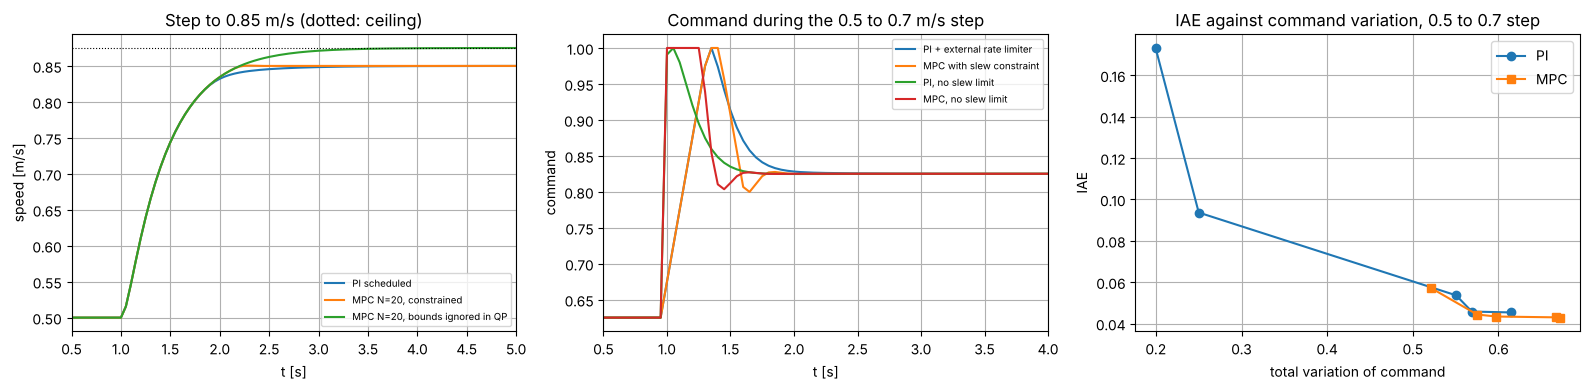

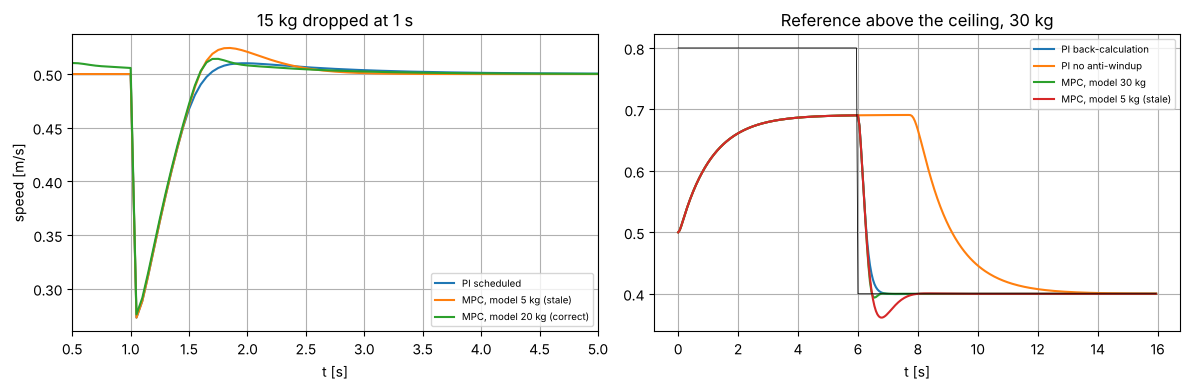

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, o in runs_b.items():
    ax[0].plot(o["t"], o["y"], label=name)
ax[0].axhline(ceil5, color="k", ls=":", lw=0.8); ax[0].set(xlim=(0.5, 5), title="Step to 0.85 m/s (dotted: ceiling)", xlabel="t [s]", ylabel="speed [m/s]"); ax[0].legend(fontsize=7)
for name, o in runs_c.items():
    ax[1].plot(o["t"], o["u"], label=name)
ax[1].set(xlim=(0.5, 4), title="Command during the 0.5 to 0.7 m/s step", xlabel="t [s]", ylabel="command"); ax[1].legend(fontsize=7)
for ctl_, mk, grp in (("PI", "o-", pi_d), ("MPC", "s-", mpc_d)):
    ax[2].plot(grp.tv, grp.iae, mk, label=ctl_)
ax[2].set(title="IAE against command variation, 0.5 to 0.7 step", xlabel="total variation of command", ylabel="IAE"); ax[2].legend()
fig.tight_layout(); figs = [save_figure(fig, EXP, "mpc_vs_pi_step_slew_frontier")]; plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, o in runs_e.items():
    ax[0].plot(o["t"], o["y"], label=name)
ax[0].set(xlim=(0.5, 5), title="15 kg dropped at 1 s", xlabel="t [s]", ylabel="speed [m/s]"); ax[0].legend(fontsize=7)
for name, o in runs_f.items():
    ax[1].plot(o["t"], o["y"], label=name)
ax[1].plot(o["t"], o["r"], "k", lw=0.6); ax[1].set(title="Reference above the ceiling, 30 kg", xlabel="t [s]"); ax[1].legend(fontsize=7)
fig.tight_layout(); figs.append(save_figure(fig, EXP, "mpc_drop_and_ceiling")); plt.show()

Left of the first figure: the three controllers reach the same force-limited rise; the constraint-ignoring optimiser then
disagrees with the plant about what it can apply. The third panel is the fair comparison: each point is one tuning, and a better controller
sits lower and to the left.

## 14. Research Discussion and Limitations

**Facts from this run (tables in section 12).**
- **Optimiser against independent mathematics.** The unconstrained first move equals the Riccati recursion to 3.2e-9 (20 random
  states, `N = 15`). The gain error against the infinite-horizon LQR gain is 0.19, 2.2e-3, 1.9e-5, 2.4e-9, 2.2e-9 for `N = 2, 5, 10, 20, 40`.
  The box-constrained QP matches bounded least squares to 2.9e-15 relative cost, with bounds active in 14 of 15 states. The rate-constrained QP has a
  KKT relative residual of at most 1.2e-5 and violates its limits by 3.5e-16.
- **Two of my first checks were wrong, not the code.** I first required the rate-constrained cost to agree with `trust-constr` within 1e-6.
  It differed by up to 7.9e-6 relative, with SLSQP the lower (better) one in all five cases; `trust-constr` is an interior-point method and stops strictly inside the feasible set.
  I replaced the check by the KKT certificate plus the statement that SLSQP is not worse. The KKT tolerance (1e-4) was set after a prototype showed 9e-6.
- **One defect in the library, found and fixed.** In the horizon sweep, three QP solves at `N = 40` were reported as failures. The cause was
  L-BFGS-B ending with an "abnormal" line-search message at a warm start that was already optimal (projected gradient 2.5e-8). The solver
  now counts a box QP as solved when the projected gradient is below 1e-6; a unit test covers the function. After the fix there are 0 failures in all runs.
- **Step toward the ceiling (0.5 to 0.85 m/s, ceiling 0.875).** Rise time is 0.751 s for PI and MPC (force-limited). Settling: PI 1.35 s, MPC 1.10 s. IAE: 0.1516 and 0.1463
  (MPC 3.5% lower). MPC that ignores the bounds in its QP requests a command up to 2.47, overshoots 7.1%, settles in 6.15 s and has IAE 0.2546, which is 74% above the constrained MPC.
- **Horizon.** On the saturated step IAE is 0.1463 for every `N` from 2 to 40, so that scenario does not test the horizon. Under the slew limit
  (0.05 per 50 ms sample), `N = 2` gives IAE 0.0765 with 8.7% overshoot, `N = 5` gives 0.0740 with 2.1%, and `N >= 10` gives 0.0739 with 1.9%.
- **Slew-limited step (0.5 to 0.7 m/s).** PI with an external rate limiter overshoots 7.6%, settles in 1.65 s, IAE 0.0857. MPC with the slew constraint
  overshoots 1.9%, settles in 0.60 s, IAE 0.0739 (14% lower). Both respect the limit: the largest command step is 0.0500.
- **Without constraints the comparison is nearly a draw.** At the default tunings MPC's IAE is 19% below PI's (0.0434 against 0.0536), but those two
  settings differ in aggressiveness. Over five tunings of each, no MPC point is dominated by a PI point in (IAE, total variation of the command), and one of five PI points is dominated by an
  MPC point (PI `tau_c = 0.05`: IAE 0.0453, TV 0.615; MPC `R = 0.01`: IAE 0.0434, TV 0.598, 4% lower IAE and 3% lower TV). The other points interleave.
- **Item drop (15 kg, model assumes 5 kg or the correct 20 kg).** The dip is 0.227 m/s and recovery 0.50 s for all three. IAE after the drop: PI scheduled 0.0779, MPC with
  the stale model 0.0800 (+2.7%), MPC with the correct model 0.0743 (-4.6%). Steady-state error of the stale-model MPC is 1.8e-8 m/s.
- **Unreachable reference (30 kg).** All reach 0.690 m/s against a ceiling of 0.691. After the reference falls to 0.4 m/s, recovery to +/-0.02 m/s is 0.35 s (MPC, correct model),
  0.50 s (PI back-calculation), 4.90 s (PI without anti-windup) and 1.20 s (MPC with the 5 kg model, undershooting to 0.361 m/s). IAE after: 0.0651, 0.0724, 0.8866, 0.0926.
- **Compute time (SciPy, this machine, not an embedded figure).** Mean QP time per sample is 0.25 to 0.55 ms across runs (the largest run mean was 0.42 ms in the
  final execution). The slowest single solve was 10.9 ms in the final run; an earlier run showed 43.8 ms once (N = 5, slew-limited), cause not investigated.
  The check therefore uses the mean, not the maximum.

**Inference (not tested here).**
- The horizon only matters here when a constraint needs look-ahead (the slew ramp). For a slower plant, a dead time or a constraint that moves with the
  state, a longer horizon would probably matter; not tested.
- MPC's small advantage on the unreachable reference probably comes from having no integrator state to wind up. The PI with back-calculation is already close.
- The undershoot of the stale-model MPC is probably the model's 5 kg inertia predicting faster deceleration than the real 30 kg belt allows. Not isolated.

**Limits.** (1) The comparison depends on how each controller is tuned; the (IAE, variation) frontier is one scenario with five settings each. (2) The MPC model uses the true plant parameters
except where a stale payload is stated, which is a best case. (3) No measurement noise was applied; the disturbance estimator with noisy speed is untested. (4) No terminal cost or set: no
stability guarantee (Mayne et al., 2000), only the closed-loop results above. (5) Single input, single output, stable plant: nothing here shows a benefit for multivariable
coupling. (6) Timing uses SciPy on one machine. (7) The PI identification constants are copied from notebook 11 rather than read from its result file, so a change there would not propagate.
(8) The PI reads the payload from an ideal load cell. (9) The convergence threshold (0.1%) and the active-bounds requirement (at least 8 of 15 states) were chosen after seeing a first run.
(10) The residual floor of about 2e-9 in the LQR gain error probably comes from the 1e-10 regularisation added to the QP Hessian; not isolated.

## 15. Summary, Exercises, and Further Research

**Key insights.** For a stable, nearly first-order plant the unconstrained MPC is an LQR with a finite horizon, and a
tuned PI is close to it; what the QP adds is exact handling of limits and a horizon for them.

**Exercises.** (1) Add a terminal cost from the DARE solution and check how a short horizon changes. (2) Replace the
output disturbance estimate by a Kalman filter with a payload state. (3) Re-build the model when the payload changes and
measure the drop recovery. (4) Measure the QP time with `qpsolvers` or OSQP in place of SciPy. (5) Add a speed-dependent
force ceiling to the constraints instead of the fixed 0 to 1 band.

**Related.** PID (03), tuning (04), DC motor (06), conveyor (11).
**Research directions.** Explicit MPC, terminal ingredients for stability, embedded QP solvers.

In [5]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="Linear MPC of a belt conveyor: horizon, constraints and comparison with PI",
    notebook="notebooks/06_advanced_control/12_mpc.ipynb",
    algorithm="Linear MPC (condensed QP, SciPy L-BFGS-B / SLSQP), offset-free via output disturbance estimate",
    application="Bench-scale belt conveyor, illustrative", plant_model="Single-mass belt with drive-force lag (RK4), model-based MPC on the linearisation",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated conveyor with illustrative parameters."},
    metrics={"gain_error_vs_lqr": {str(k): v for k, v in gain_err.items()}, "step_to_ceiling": rows_b, "horizon_sweep": rows_h, "horizon_sweep_slew": rows_h2, "slew_step": rows_c,
             "tuning_frontier": rows_d, "frontier_dominance": {"mpc_points_dominated_by_pi": dominated, "pi_points_dominated_by_mpc": dominating},
             "item_drop": rows_e, "unreachable_reference": df_f.reset_index().to_dict("records"), "worst_qp_ms": float(worst_ms), "worst_run_mean_qp_ms": float(mean_ms_all)},
    checks=checks, sampling_time_s=Ts, random_seed=12, number_of_trials=len(rows_b) + len(rows_h) + len(rows_c) + len(rows_d) + len(rows_e) + len(rows_f),
    controller_parameters={"mpc": {"N": 20, "Q": 1.0, "R": 0.01, "u_limits": [0.0, 1.0], "slew_per_sample": DU}, "pi": {"tau_c_s": 0.2}},
    plant_parameters=P.as_dict(), input_configuration={"operating_speed_m_s": V0, "steps": [0.85, 0.7]},
    disturbance_configuration={"item_drop_kg": 15.0, "at_s": 1.0, "initial_payload_kg": 5.0},
    operating_conditions={"solver": "SciPy L-BFGS-B / SLSQP", "ideal_load_cell_for_pi": True},
    figure_references=figs,
    limitations=["Illustrative plant parameters.", "No terminal cost or set: no stability guarantee.", "General-purpose SciPy solver; timing is for this machine only.",
                 "MPC model uses the true plant parameters (best case) except where a stale payload is stated.", "PI and MPC tuned by different rules; compared on IAE against command variation.",
                 "Single input, single output, stable plant: no multivariable benefit tested.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_12_mpc_conveyor.json
